# 2 · Inputs

Notebook 1 changed the model. This notebook changes what the model reads.

So far it has read four raw numbers per pixel, divided by 10,000 because we were told to. A person telling water from forest would not squint at raw numbers; they would use what is known about light: plants reflect near-infrared strongly, and water absorbs it. Let us give the model the same head start, train it, and check whether it helps, first in the scores and then on a map.

Fetching 603 files:   0%|          | 0/603 [00:00<?, ?it/s]

:Layout
   .RGB.I   :RGB   [x,y]   (R,G,B)
   .Image.I :Image   [x,y]   (label)
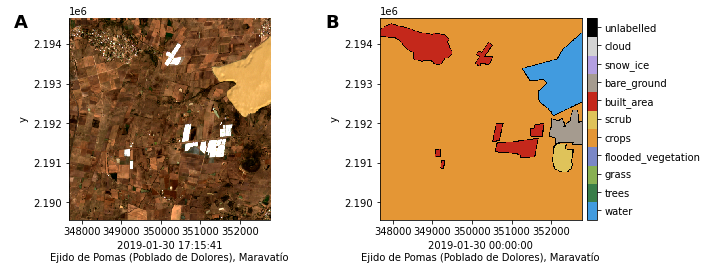

In [1]:
from pathlib import Path

from huggingface_hub import snapshot_download

import geosave_engine as gs

root = Path(snapshot_download("fatmur/dynamicworld-300", repo_type="dataset", local_dir="data/dynamic_world"))

images = sorted((root / "val/images").glob("*.tif"))
labels = sorted((root / "val/labels").glob("*.tif"))

image = gs.open_raster(images[0]).isel(time=0)
label = gs.open_raster(labels[0])["label"].isel(time=0)

image.gs.plot() + label.gs.plot()

## What are the four numbers?

Before improving the inputs we need to know what they are. The file says: each band records which light it measured. `B08` is near-infrared, the light plants reflect strongly.

In [2]:
image.gs.spectral

{'B02': Spectral(common_name='blue', center_wavelength=0.49, full_width_half_max=0.098),
 'B03': Spectral(common_name='green', center_wavelength=0.56, full_width_half_max=0.045),
 'B04': Spectral(common_name='red', center_wavelength=0.665, full_width_half_max=0.038),
 'B08': Spectral(common_name='nir', center_wavelength=0.842, full_width_half_max=0.145)}

## From stored numbers to reflectance

The files store reflectance, the share of light reflected, as whole numbers times 10,000. That scale is written in the file too, so `mask_and_scale()` can apply it instead of our hand-written `/ 10_000`. It also blanks pixels with no measurement as NaN, where dividing would have left a misleading 0.

The values now sit between 0 and 1:

In [3]:
reflectance = image.gs.mask_and_scale()
reflectance.gs.statistics()

,minimum,maximum,mean,stddev,valid_percent
B02,0.0019,0.5288,0.063051,0.041067,100.0
B03,0.0111,0.4964,0.091208,0.042801,100.0
B04,0.0160,0.4696,0.122140,0.044445,100.0
B08,0.0212,0.5724,0.196409,0.053222,100.0


## Hints for vegetation and water

Plants absorb red and reflect near-infrared, so **NDVI** = (nir − red) / (nir + red) is high over vegetation and low over bare ground and water. **NDWI** = (green − nir) / (green + nir) does the same for water. `gs.features` has both; we name which band is which light.

Compare them with the label: each index already outlines a few classes the model has to learn.

:Layout
   .Image.I   :Image   [x,y]   (label)
   .Image.II  :Image   [x,y]   (value)
   .Image.III :Image   [x,y]   (value)
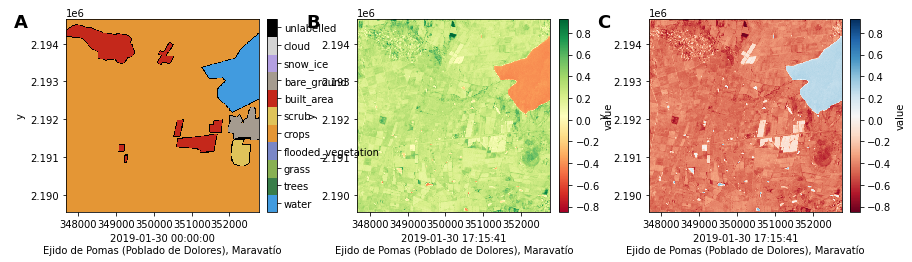

In [4]:
ndvi = gs.features.ndvi(reflectance, nir="B08", red="B04")
ndwi = gs.features.ndwi(reflectance, green="B03", nir="B08")

(label.gs.plot() + ndvi.gs.plot(cmap="RdYlGn") + ndwi.gs.plot(cmap="RdBu")).cols(3)

## The new inputs

`prepare` turns a tile into the model's inputs: reflectance plus the two indices, added as bands with `assign`. Reflectance sits between 0 and 1 and the indices between -1 and 1, so the bands are already on a similar footing for the model. Bands are named, so trying another choice is a matter of names, such as `reflectance[["B04", "B03", "B02"]]` for RGB only.

In [5]:
def prepare(image):
    reflectance = image.gs.mask_and_scale()
    ndvi = gs.features.ndvi(reflectance, nir="B08", red="B04")
    ndwi = gs.features.ndwi(reflectance, green="B03", nir="B08")
    return reflectance.assign(ndvi=ndvi, ndwi=ndwi)


inputs = prepare(image)
inputs.gs.variables

('B02', 'B03', 'B04', 'B08', 'ndvi', 'ndwi')

## Training on six bands

The dataset is notebook 0's with `prepare` in place of `/ 10_000`. Pixels the satellite did not measure are NaN after `mask_and_scale()`; `nan_to_num(0)` turns them into zeros the model can read. The model is notebook 0's too, with its first layer reading six bands instead of four.

In [6]:
import torch
from torch.utils.data import DataLoader, Dataset


class Tiles(Dataset):
    def __init__(self, split):
        self.images = sorted((root / split / "images").glob("*.tif"))
        self.labels = sorted((root / split / "labels").glob("*.tif"))

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):
        image = gs.open_raster(self.images[index]).isel(time=0)
        label = gs.open_raster(self.labels[index])["label"].isel(time=0)
        return prepare(image).gs.to_tensor(dtype="float32").nan_to_num(0), label.gs.to_tensor(dtype="int64")


train_loader = DataLoader(Tiles("train"), batch_size=8, shuffle=True)
val_loader = DataLoader(Tiles("val"), batch_size=8)

pixels, classes = Tiles("train")[0]
pixels.shape, classes.shape

(torch.Size([6, 510, 510]), torch.Size([510, 510]))

In [7]:
import lightning as L
from torch import nn
from torchmetrics import MetricCollection
from torchmetrics.classification import MulticlassAccuracy, MulticlassJaccardIndex


class Segmenter(L.LightningModule):
    def __init__(self, bands):
        super().__init__()
        self.model = nn.Sequential(
            nn.Conv2d(bands, 16, 3, stride=2, padding=1), nn.ReLU(),
            nn.Upsample(scale_factor=2), nn.Conv2d(16, 16, 3, padding=1), nn.ReLU(),
            nn.Conv2d(16, 10, 1),
        )
        self.val_metrics = MetricCollection(
            {
                "miou": MulticlassJaccardIndex(num_classes=10, ignore_index=255),
                "accuracy": MulticlassAccuracy(num_classes=10, ignore_index=255, average="micro"),
            },
            prefix="val_",
        )
        self.criterion = nn.CrossEntropyLoss(ignore_index=255)

    def forward(self, image):
        return self.model(image)

    def training_step(self, batch, batch_index):
        image, label = batch
        loss = self.criterion(self(image), label)
        self.log("train_loss", loss)
        return loss

    def validation_step(self, batch, batch_index):
        image, label = batch
        logits = self(image)
        self.log("val_loss", self.criterion(logits, label))
        self.val_metrics(logits, label)
        self.log_dict(self.val_metrics)

    def configure_optimizers(self):
        return torch.optim.AdamW(self.parameters(), lr=1e-2)


module = Segmenter(bands=len(inputs.gs.variables))
module

Segmenter(
  (model): Sequential(
    (0): Conv2d(6, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
    (2): Upsample(scale_factor=2.0, mode='nearest')
    (3): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): Conv2d(16, 10, kernel_size=(1, 1), stride=(1, 1))
  )
  (val_metrics): MetricCollection(
    (accuracy): MulticlassAccuracy()
    (miou): MulticlassJaccardIndex(),
    prefix=val_
  )
  (criterion): CrossEntropyLoss()
)

In [8]:
import warnings

from lightning.pytorch.loggers import TensorBoardLogger

# The tiles are small and few; Lightning's hint to add loader workers is noise here.
warnings.filterwarnings("ignore", ".*does not have many workers.*")

L.seed_everything(0)
trainer = L.Trainer(
    max_epochs=6,
    limit_train_batches=6,
    limit_val_batches=2,
    log_every_n_steps=1,
    logger=TensorBoardLogger("lightning_logs", name="", version="inputs"),
)
trainer.fit(module, train_loader, val_loader)

Seed set to 0


GPU available: False, used: False


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.


...

Trainable params: 3.4 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 3.4 K                                                                                                
Total estimated model params size (MB): 0                                                                          
Modules in train mode: 11                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

/home/uwu/Projects/geosave-engine/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/_pytree.py:21: 
`isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` 
instead.

/home/uwu/Projects/geosave-engine/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/_pytree.py:21: 
`isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` 
instead.

`Trainer.fit` stopped: `max_epochs=6` reached.


## Did it help?

This run logs to `lightning_logs/inputs/`, beside notebooks 0 and 1. Compare `val_miou` across the runs: the same small model, given reflectance and two indices instead of raw numbers.

In [9]:
%load_ext tensorboard
%tensorboard --logdir lightning_logs

Scores summarise every tile; a map shows where the model is right and wrong. Predict the first validation batch and keep the best-scoring class at each pixel. The loader is not shuffled, so the first prediction belongs to the tile shown at the top. `label.copy(data=...)` puts the classes on the label's grid and keeps its class names and colours.

:Layout
   .Image.I  :Image   [x,y]   (label)
   .Image.II :Image   [x,y]   (prediction)
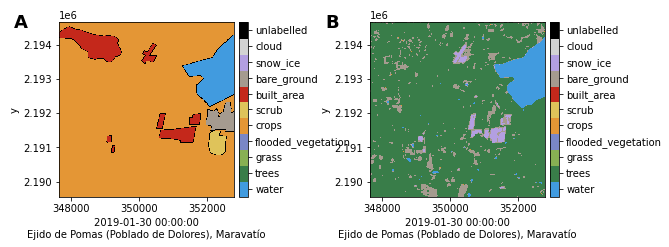

In [10]:
images, _ = next(iter(val_loader))
module.eval()
with torch.no_grad():
    prediction = module(images).argmax(1)[0]

predicted = label.copy(data=prediction.numpy().astype("uint8")).rename("prediction")

label.gs.plot() + predicted.gs.plot()

To look at it in context, or hand it to someone using QGIS, save it as a Cloud-Optimized GeoTIFF. It keeps its position and class names, so reopening it lands it on a real map; zoom out to see where on Earth this tile is.

In [11]:
files = predicted.gs.to_cog("predicted.tif", overwrite=True)
gs.open_raster(files).gs.explore()

/home/uwu/Projects/geosave-engine/.venv/lib/python3.12/site-packages/rasterio/warp.py:385: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dest = _reproject(


BokehModel(combine_events=True, render_bundle={'docs_json': {'5c826216-55cb-4907-b482-94cf279d70fc': {'version…

## What happened

We replaced the hand-written `/ 10_000` with reflectance read from the file, added two indices that outline vegetation and water, trained the same small model on them, and compared the runs. The prediction went back on the tile's grid as a map that opens anywhere.

Our tiles stop us going further. They were chosen cloud-free, and real imagery is not. And the pretrained encoder from notebook 1 reads each pixel's date and location as well as its bands. Both mean fetching imagery ourselves.

| Next | Question |
| --- | --- |
| 3 · Your own data | How do I fetch imagery for my own labels, places and dates? |